# Filled data overview

An overview of `data/processed/hourly_filled.parquet`: the cleaned hourly electricity use for
factories A–D in 2022, with the missing weeks at the end of the year filled with estimates.

In every chart, **coloured lines are real measurements** and **grey lines are estimated values**
(`is_imputed == True`). See `data/processed/README.md` for how the estimates were made.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

FACTORIES = ["A", "B", "C", "D"]
COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "D": "#eda100"}  # fixed per factory
MUTED = "#a3a29c"      # estimated values
INK_2 = "#52514e"
PROBLEM_FILL = "#e3e2dc"  # shading for estimated periods
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_2,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e8e7e1",
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
    "font.size": 9,
})

filled = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "hourly_filled.parquet")
series = {f: g.set_index("timestamp")["kwh"] for f, g in filled.groupby("factory")}
imputed = {f: g.set_index("timestamp")["is_imputed"] for f, g in filled.groupby("factory")}
daily = {f: s.resample("D").mean() for f, s in series.items()}
daily_imputed = {f: m.resample("D").max() for f, m in imputed.items()}

def shade(ax, start, end, label=None):
    """Shade an estimated period on a time axis."""
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=PROBLEM_FILL, zorder=0, lw=0)
    if label:
        ax.text(pd.Timestamp(start), ax.get_ylim()[1], " " + label, va="top", ha="left",
                color=INK_2, fontsize=8)

## 1. Summary

One row per factory. Every factory now has a value for every hour of 2022 (8,760 hours).

In [2]:
rows = []
for f in FACTORIES:
    s, m = series[f], imputed[f]
    rows.append({
        "factory": f,
        "hours": len(s),
        "real hours": int((~m).sum()),
        "estimated hours": int(m.sum()),
        "estimated (%)": round(100 * m.mean(), 1),
        "estimated from": f"{m[m].index.min():%d %b %H:%M}" if m.any() else "–",
        "mean kWh/h": round(s.mean(), 1),
        "min": round(s.min(), 1),
        "max": round(s.max(), 1),
    })
pd.DataFrame(rows).set_index("factory")

,hours,real hours,estimated hours,estimated (%),estimated from,mean kWh/h,min,max
factory,,,,,,,,
A,8760,8760,0,0.0,–,179.0,1.2,374.1
B,8760,7958,802,9.2,28 Nov 14:00,143.6,94.8,300.1
C,8760,7800,960,11.0,22 Nov 00:00,139.2,25.0,790.0
D,8760,8760,0,0.0,–,105.0,40.0,256.0


## 2. The whole year

Daily mean per hour. The grey part at the end of the year for B and C is estimated.

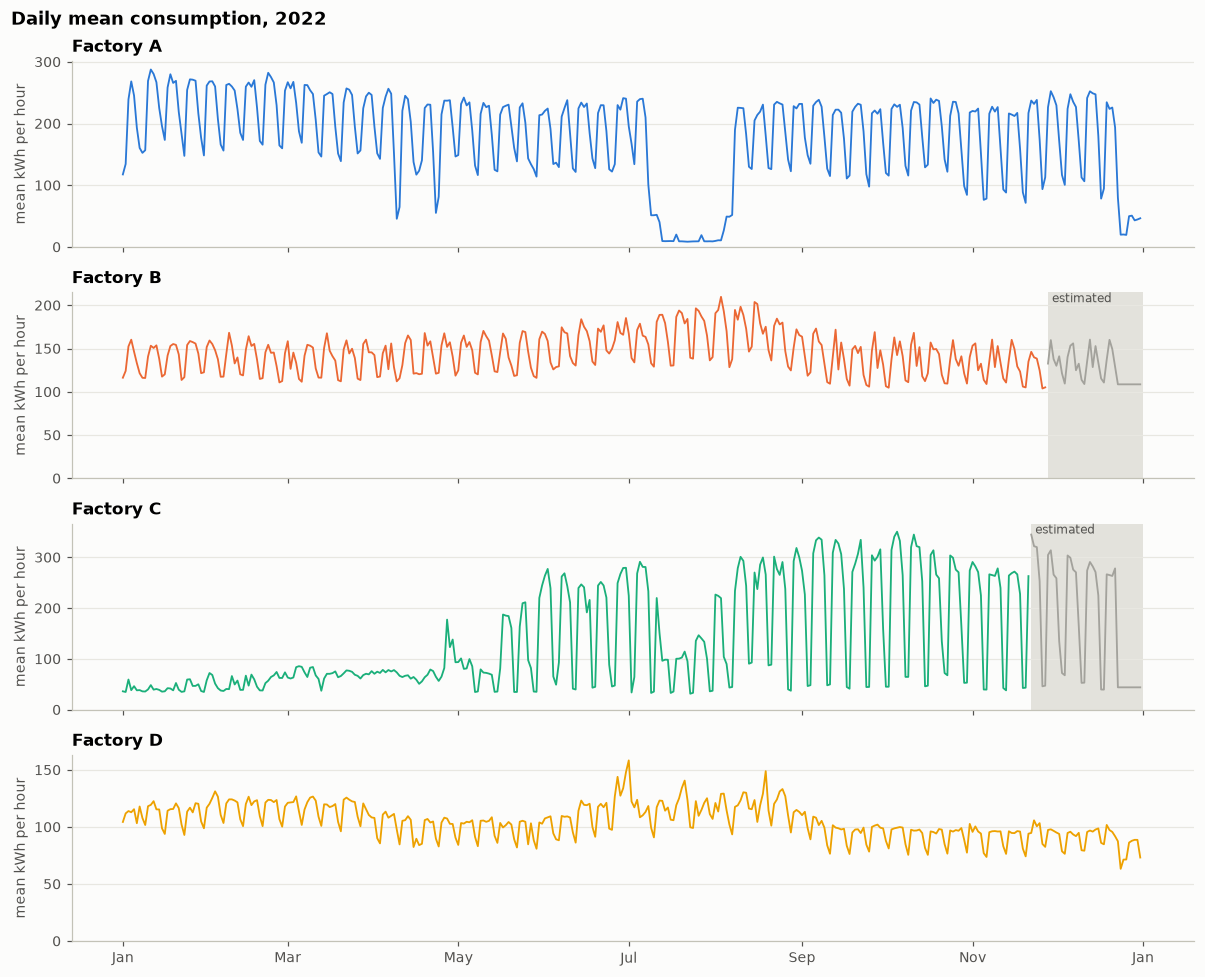

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, f in zip(axes, FACTORIES):
    d, est = daily[f], daily_imputed[f]
    ax.plot(d.index, d.where(~est), color=COLORS[f], lw=1.2)
    ax.plot(d.index, d.where(est), color=MUTED, lw=1.2)
    ax.set_title(f"Factory {f}")
    ax.set_ylabel("mean kWh per hour")
    ax.set_ylim(bottom=0)
    if est.any():
        shade(ax, est[est].index.min(), "2023-01-01", "estimated")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.suptitle("Daily mean consumption, 2022", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()

## 3. Close-up of the estimated weeks (B and C)

Hourly values from mid-October. Until 22 December the gap is filled by copying the real weeks just
before it. From 23 December a typical weekend day is repeated, because factories A and D show a
Christmas shutdown from that date.

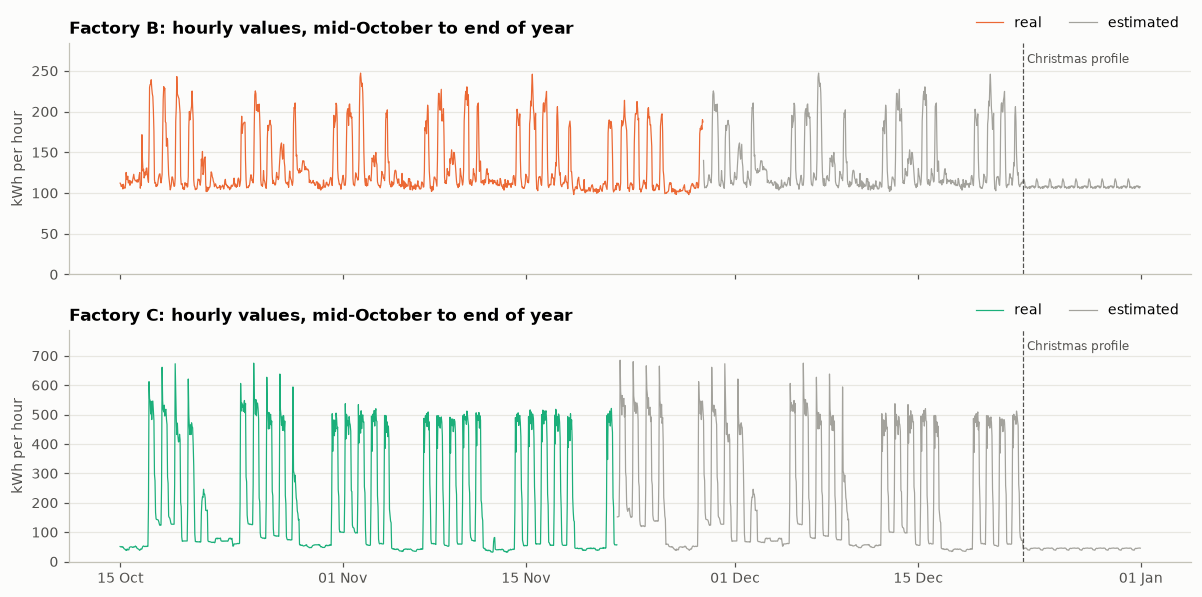

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, f in zip(axes, ["B", "C"]):
    s, m = series[f]["2022-10-15":], imputed[f]["2022-10-15":]
    ax.plot(s.index, s.where(~m), color=COLORS[f], lw=0.8, label="real")
    ax.plot(s.index, s.where(m), color=MUTED, lw=0.8, label="estimated")
    ax.axvline(pd.Timestamp("2022-12-23"), color=INK_2, lw=0.8, ls="--")
    ax.text(pd.Timestamp("2022-12-23"), s.max() * 1.05, " Christmas profile", color=INK_2, fontsize=8)
    ax.set_ylim(0, s.max() * 1.15)
    ax.set_title(f"Factory {f}: hourly values, mid-October to end of year")
    ax.set_ylabel("kWh per hour")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=2)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.tight_layout()

## 4. A typical week

Mean consumption for each hour of the week (Monday 00:00 to Sunday 23:00), using **real hours only**.
This shows the daily rhythm and how much lower weekends are.

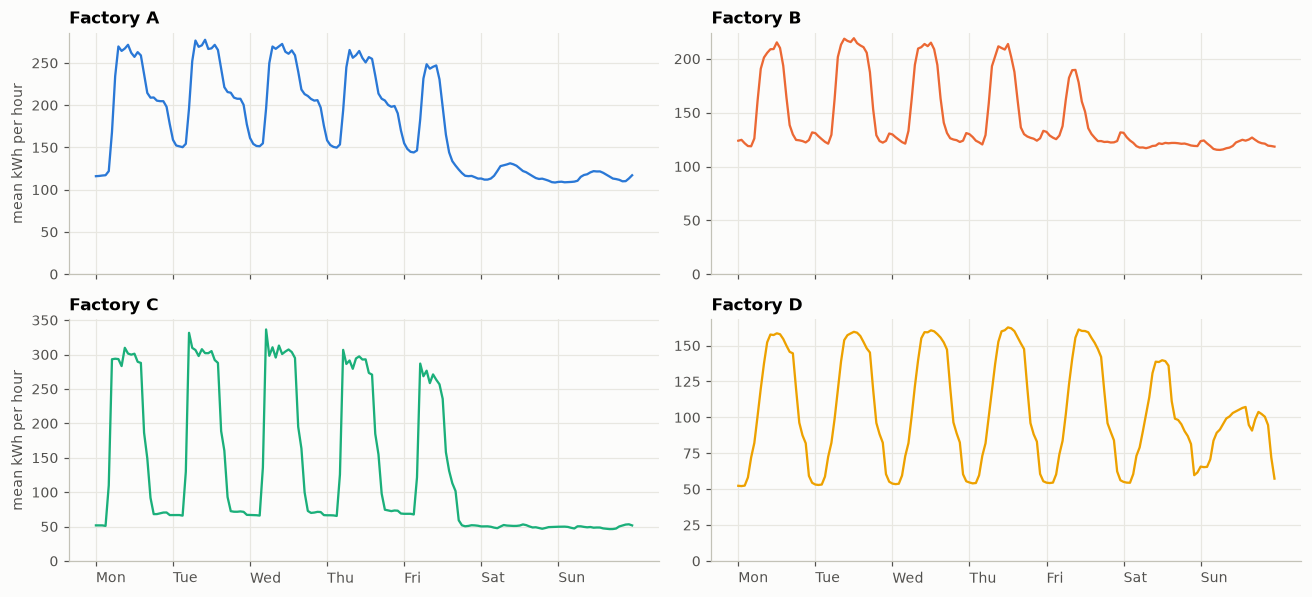

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for ax, f in zip(axes.flat, FACTORIES):
    s = series[f][~imputed[f]]
    week = s.groupby(s.index.day_of_week * 24 + s.index.hour).mean()
    ax.plot(week.index, week.values, color=COLORS[f])
    ax.set_title(f"Factory {f}")
    ax.set_ylim(bottom=0)
    ax.set_xticks(range(0, 168, 24), WEEKDAYS, ha="left")
    ax.grid(axis="x", visible=True)
for ax in axes[:, 0]:
    ax.set_ylabel("mean kWh per hour")
fig.tight_layout()

## 5. Monthly mean

Grey bars contain estimated values. Factory C is much lower before mid-May; that is real and was
**not** changed (see notes below).

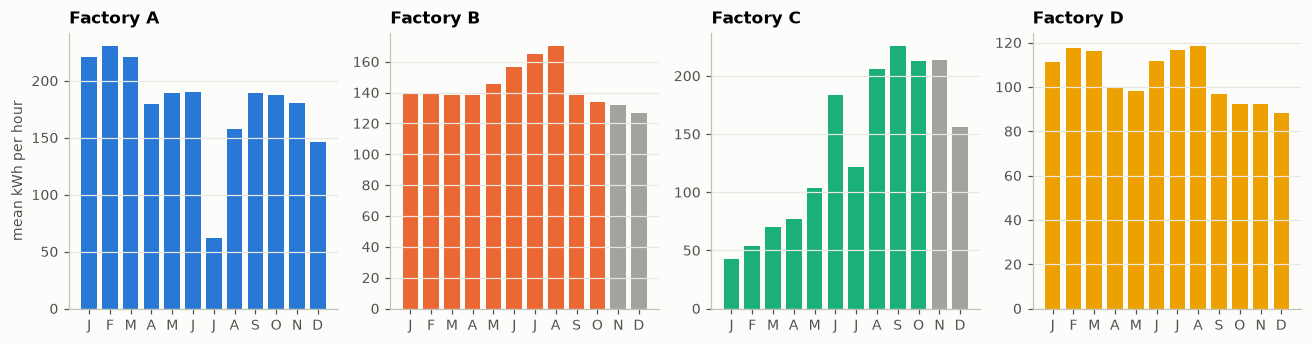

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=False)
for ax, f in zip(axes, FACTORIES):
    monthly = series[f].resample("MS").mean()
    has_est = imputed[f].resample("MS").max()
    ax.bar(range(12), monthly, color=[MUTED if e else COLORS[f] for e in has_est], width=0.75)
    ax.set_xticks(range(12), [m[0] for m in monthly.index.strftime("%b")])
    ax.set_title(f"Factory {f}")
axes[0].set_ylabel("mean kWh per hour")
fig.tight_layout()